# Sign Language Detector: ASL Alphabet Preprocessing
Dataset: [ASL Alphabet](https://www.kaggle.com/datasets/grassknoted/asl-alphabet) (87,000 labeled 200x200 RGB images, 29 classes: A-Z, `del`, `nothing`, `space`).

Steps: build a file manifest, validate every image, explore class balance, stratified train/val/test split, resize to 28x28 grayscale for the Random Forest/CNN baselines, and build a folder layout for YOLO classification.

The raw images (1.2 GB) live outside the OneDrive project folder, in `~/ml-data/asl-alphabet`. Set `ASL_DATA_DIR` to use a different location.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split

SEED = 42
DATA_DIR = Path(os.environ.get("ASL_DATA_DIR", Path.home() / "ml-data/asl-alphabet"))
TRAIN_DIR = DATA_DIR / "asl_alphabet_train" / "asl_alphabet_train"
OUT_DIR = Path("processed")
OUT_DIR.mkdir(exist_ok=True)
SIZE = 28  # matches Sign Language MNIST so the baselines can share code

## 1. Build the manifest
One row per image: path (relative to the train folder) and class name.

In [2]:
rows = [(str(p.relative_to(TRAIN_DIR)), p.parent.name)
        for p in sorted(TRAIN_DIR.glob("*/*.jpg"))]
manifest = pd.DataFrame(rows, columns=["path", "label"])
classes = sorted(manifest["label"].unique())
manifest["y"] = manifest["label"].map({c: i for i, c in enumerate(classes)})
print(len(manifest), "images,", len(classes), "classes")
print(classes)

87000 images, 29 classes
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


## 2. Validate
Check every image opens and has the expected size and colour mode, and that no file is duplicated.

In [3]:
bad, sizes, modes = [], set(), set()
for p in manifest["path"]:
    try:
        with Image.open(TRAIN_DIR / p) as im:
            im.verify()
        with Image.open(TRAIN_DIR / p) as im:
            sizes.add(im.size)
            modes.add(im.mode)
    except Exception as e:
        bad.append((p, repr(e)))
print("unreadable:", len(bad), "| sizes:", sizes, "| modes:", modes)
print("duplicate paths:", manifest["path"].duplicated().sum())

unreadable: 0 | sizes: {(200, 200)} | modes: {'RGB'}
duplicate paths: 0


## 3. Class distribution

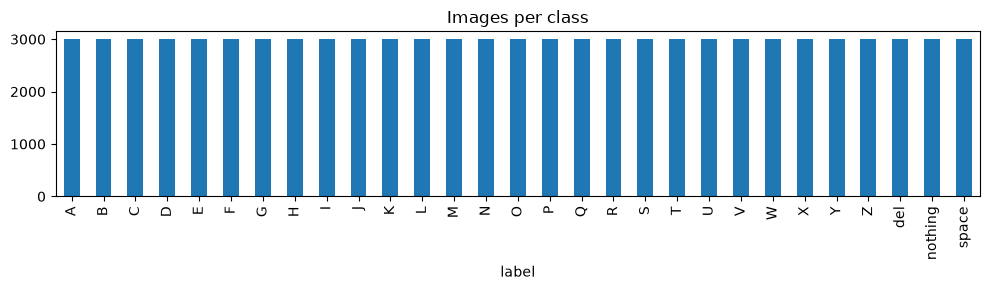

count      29.0
mean     3000.0
std         0.0
min      3000.0
25%      3000.0
50%      3000.0
75%      3000.0
max      3000.0
Name: count, dtype: float64

In [4]:
counts = manifest["label"].value_counts().sort_index()
ax = counts.plot.bar(figsize=(10, 3), title="Images per class")
ax.figure.tight_layout()
ax.figure.savefig(OUT_DIR / "asl_class_distribution.png", dpi=120)
plt.show()
counts.describe()

## 4. Train / validation / test split
Stratified 70 / 15 / 15.

**Caveat:** the images are consecutive frames of a few short recordings per letter, so near-identical frames can land in different splits and inflate validation/test accuracy. The 28 official test images are a separate sanity check we can use alongside this split.

In [5]:
train_df, rest = train_test_split(
    manifest, test_size=0.30, stratify=manifest["y"], random_state=SEED)
val_df, test_df = train_test_split(
    rest, test_size=0.50, stratify=rest["y"], random_state=SEED)
manifest["split"] = "train"
manifest.loc[val_df.index, "split"] = "val"
manifest.loc[test_df.index, "split"] = "test"
manifest.to_csv(OUT_DIR / "asl_alphabet_manifest.csv", index=False)
print(manifest["split"].value_counts())

split
train    60900
val      13050
test     13050
Name: count, dtype: int64


## 5. Sample images

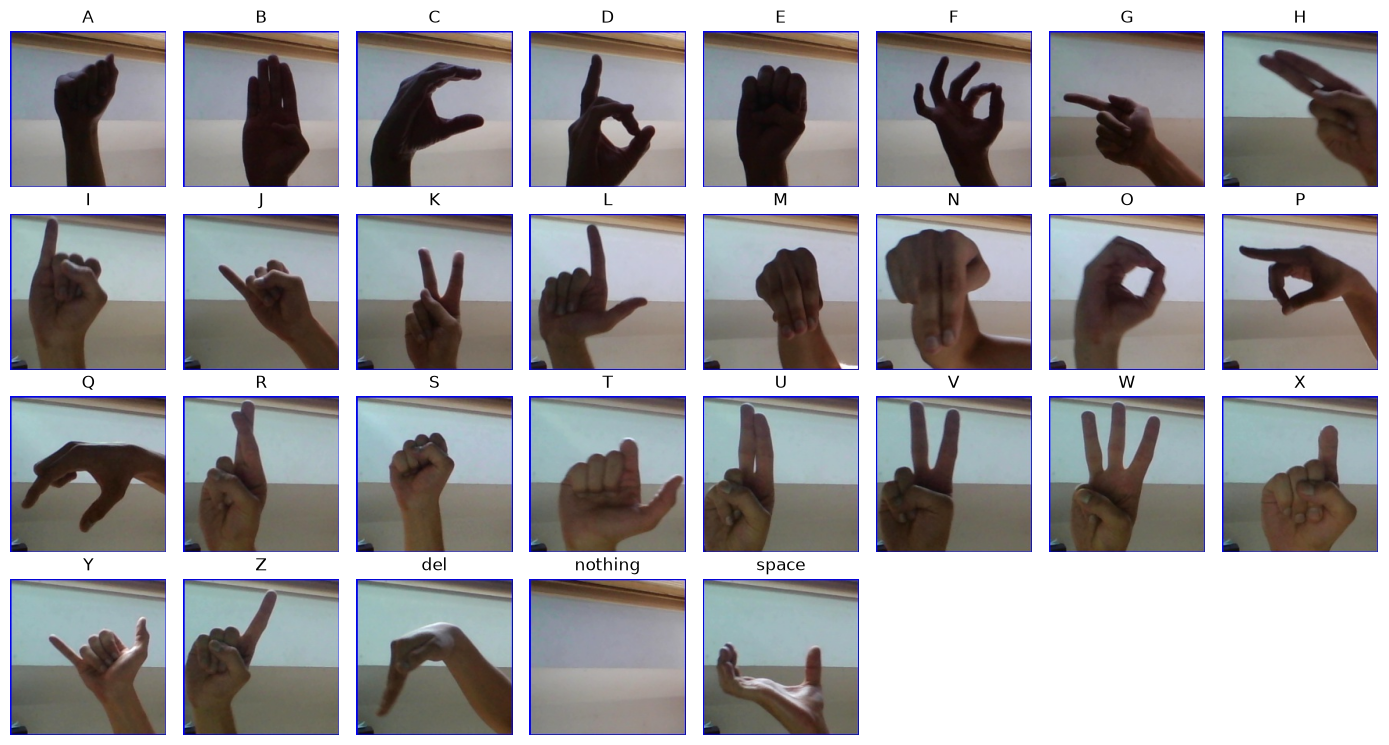

In [6]:
fig, axes = plt.subplots(4, 8, figsize=(14, 7.5))
for ax in axes.ravel():
    ax.axis("off")
for i, c in enumerate(classes):
    p = manifest.loc[manifest["label"] == c, "path"].iloc[0]
    axes.ravel()[i].imshow(Image.open(TRAIN_DIR / p))
    axes.ravel()[i].set_title(c)
fig.tight_layout()
fig.savefig(OUT_DIR / "asl_samples.png", dpi=100)
plt.show()

## 6. Resize to 28x28 grayscale
Pixels are scaled to [0, 1] as float32 and shaped `(N, 28, 28, 1)`, the same format as notebook 1.

In [7]:
def load_small(path):
    with Image.open(TRAIN_DIR / path) as im:
        im = im.convert("L").resize((SIZE, SIZE), Image.LANCZOS)
        return np.asarray(im, dtype=np.uint8)

X = np.stack([load_small(p) for p in manifest["path"]])
X = (X / 255.0).astype(np.float32).reshape(-1, SIZE, SIZE, 1)
y = manifest["y"].to_numpy()
print(X.shape, X.min(), X.max())

(87000, 28, 28, 1) 0.0 1.0


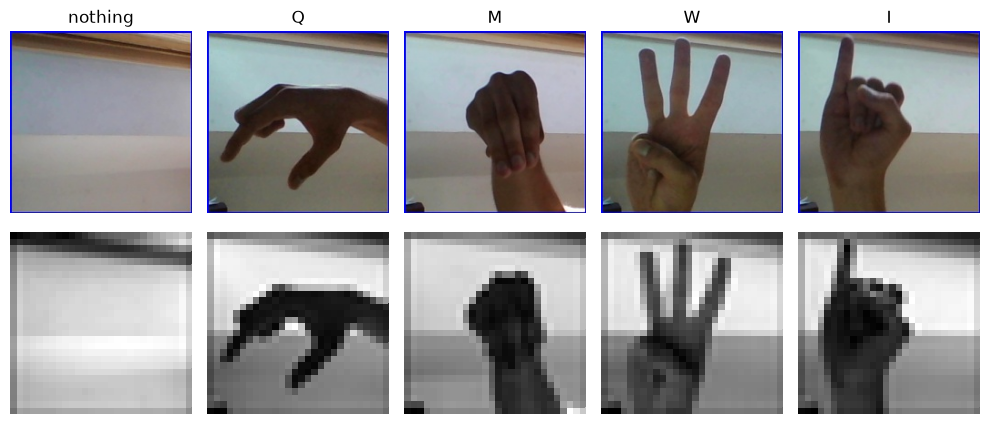

In [8]:
# Before / after: original 200x200 RGB vs 28x28 grayscale
ex = manifest.groupby("label").head(1).sample(5, random_state=SEED)
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for j, (idx, r) in enumerate(ex.iterrows()):
    axes[0, j].imshow(Image.open(TRAIN_DIR / r["path"]))
    axes[0, j].set_title(r["label"])
    axes[1, j].imshow(X[idx].squeeze(), cmap="gray")
    axes[0, j].axis("off"); axes[1, j].axis("off")
fig.tight_layout()
plt.show()

## 7. Save arrays

In [9]:
s = manifest["split"].to_numpy()
np.savez_compressed(
    OUT_DIR / "asl_alphabet_processed.npz",
    X_train=X[s == "train"], y_train=y[s == "train"],
    X_val=X[s == "val"], y_val=y[s == "val"],
    X_test=X[s == "test"], y_test=y[s == "test"],
    classes=np.array(classes),
)
print({k: int((s == k).sum()) for k in ["train", "val", "test"]})

{'train': 60900, 'val': 13050, 'test': 13050}


## 8. YOLO classification layout
The dataset has no bounding boxes (each image is a single hand), so we use YOLO in classification mode, which expects `train/`, `val/` and `test/` folders with one subfolder per class and needs no annotation files. Symlinks keep it from duplicating 1.2 GB. The result is written outside OneDrive.

In [10]:
YOLO_DIR = Path.home() / "ml-data" / "asl-yolo-cls"
for _, r in manifest.iterrows():
    dst = YOLO_DIR / r["split"] / r["label"] / Path(r["path"]).name
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        dst.symlink_to((TRAIN_DIR / r["path"]).resolve())
print(YOLO_DIR, sum(1 for _ in YOLO_DIR.rglob("*.jpg")), "links")

/Users/anyaasutaria/ml-data/asl-yolo-cls 87000 links
